Dominant Color Name: Big Dip O’Ruby
RGB from CSV: (156, 37, 66)
Hex from CSV: #9c2542


/tmp/ipython-input-1417572793.py:32: RuntimeWarning: overflow encountered in scalar subtract
  d = abs(R - int(colors.loc[i, "R"])) + abs(G - int(colors.loc[i, "G"])) + abs(B - int(colors.loc[i, "B"]))
/tmp/ipython-input-1417572793.py:32: RuntimeWarning: overflow encountered in scalar add
  d = abs(R - int(colors.loc[i, "R"])) + abs(G - int(colors.loc[i, "G"])) + abs(B - int(colors.loc[i, "B"]))


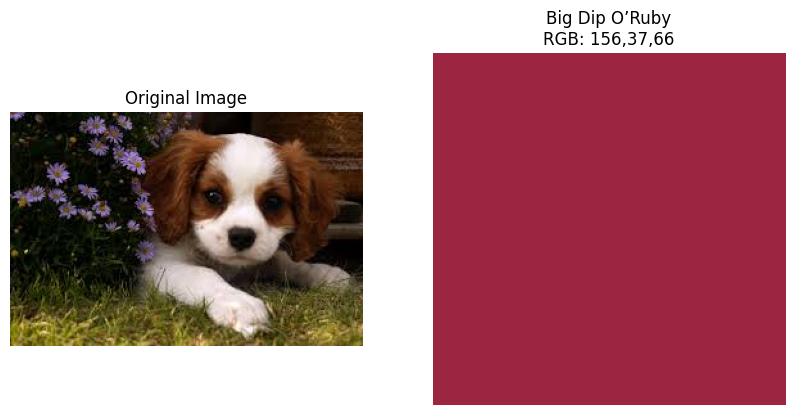

In [4]:
# === Step 1: Import Libraries ===
import cv2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

# === Step 2: Load the color dataset ===
index = ['color_id', 'color_name', 'hex', 'R', 'G', 'B']
colors = pd.read_csv('colors.csv', names=index, header=None)

# === Step 3: Load your image ===
img = cv2.imread('sample2.jpg')
img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# Optional: Resize large images for faster processing
img_resized = cv2.resize(img, (800, 800))

# === Step 4: Find the dominant color (raw RGB) ===
pixels = img_resized.reshape(-1, 3)
pixels_list = [tuple(pixel) for pixel in pixels]
most_common = Counter(pixels_list).most_common(1)[0][0]
R, G, B = most_common

# === Step 5: Function to find closest color name & RGB from CSV ===
def get_color_name_and_rgb(R, G, B):
    minimum = 10000
    cname = ""
    hex_value = ""
    R_match = G_match = B_match = 0
    for i in range(len(colors)):
        d = abs(R - int(colors.loc[i, "R"])) + abs(G - int(colors.loc[i, "G"])) + abs(B - int(colors.loc[i, "B"]))
        if d < minimum:
            minimum = d
            cname = colors.loc[i, "color_name"]
            hex_value = colors.loc[i, "hex"]
            R_match = int(colors.loc[i, "R"])
            G_match = int(colors.loc[i, "G"])
            B_match = int(colors.loc[i, "B"])
    return cname, hex_value, R_match, G_match, B_match

color_name, hex_code, R_csv, G_csv, B_csv = get_color_name_and_rgb(R, G, B)

# === Step 6: Display Results ===
print(f"Dominant Color Name: {color_name}")
print(f"RGB from CSV: ({R_csv}, {G_csv}, {B_csv})")
print(f"Hex from CSV: {hex_code}")

# === Step 7: Show Image and Detected Color ===
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].imshow(img)
ax[0].set_title('Original Image')
ax[0].axis('off')

color_patch = np.zeros((100, 100, 3), dtype=np.uint8)
color_patch[:, :] = [R_csv, G_csv, B_csv]
ax[1].imshow(color_patch)
ax[1].set_title(f'{color_name}\nRGB: {R_csv},{G_csv},{B_csv}')
ax[1].axis('off')

plt.show()
